# Beyond the Chains
## 03 — NFL Dataset Exploration & Variable Audit (2000–2025)

### Research Objective

This notebook examines the structure, completeness, and analytical potential of the NFL weekly team-statistics dataset covering the 2000–2025 seasons.

The purpose is to identify available variables, assess data quality, and organize the dataset for subsequent team-level, matchup-based, and predictive analyses.


In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Locate project root
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load existing dataset
team_stats = pd.read_parquet(
    ROOT / "data" / "processed" / "team_stats_2000_2025.parquet"
)

print("Dataset shape:", team_stats.shape)
print("Number of columns:", team_stats.shape[1])
print("Available seasons:", team_stats["season"].min(),
      "-", team_stats["season"].max())

display(team_stats.head())


Dataset shape: (13418, 138)
Number of columns: 138
Available seasons: 2000 - 2025


,season,week,team,season_type,game_id,opponent_team,completions,attempts,passing_yards,passing_tds,...,pt_yards,pt_inside_20,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards
0,2000,1,ARI,REG,2000_01_ARI_NYG,NYG,28,49,318,2,...,211,1,0,0,0,2,3,18,0,193
1,2000,1,ATL,REG,2000_01_SF_ATL,SF,16,31,264,2,...,95,0,0,0,1,0,1,0,0,75
2,2000,1,BAL,REG,2000_01_BAL_PIT,PIT,18,32,199,1,...,281,4,2,1,2,2,0,0,0,241
3,2000,1,BUF,REG,2000_01_TEN_BUF,TEN,13,26,174,1,...,375,2,1,0,0,2,6,60,0,315
4,2000,1,CAR,REG,2000_01_CAR_WAS,WAS,17,26,183,1,...,214,2,0,0,0,2,3,15,0,199


In [6]:

# Dataset variable audit

variable_audit = pd.DataFrame({
    "Variable": team_stats.columns,
    "Data Type": team_stats.dtypes.astype(str).values,
    "Missing Count": team_stats.isna().sum().values,
    "Missing (%)": (
        team_stats.isna().mean().values * 100
    ).round(2),
    "Unique Values": team_stats.nunique(dropna=True).values
})

display(variable_audit)



# Check duplicate team-game records

duplicates = team_stats.duplicated(
    subset=["game_id", "team"],
    keep=False
)

print("Duplicate team-game rows:", duplicates.sum())

display(
    team_stats.loc[
        duplicates,
        ["season", "week", "game_id", "team", "opponent_team"]
    ]
)


game_counts = (
    team_stats.groupby("game_id")["team"]
    .nunique()
)

print("Games with exactly two teams:", (game_counts == 2).sum())
print("Games with other team counts:", (game_counts != 2).sum())

display(game_counts[game_counts != 2])



for index, column in enumerate(team_stats.columns, start=1):
    print(f"{index:3d}. {column}")



,Variable,Data Type,Missing Count,Missing (%),Unique Values
0,season,int32,0,0.0,26
1,week,int32,0,0.0,18
2,team,str,0,0.0,32
3,season_type,str,0,0.0,1
4,game_id,str,0,0.0,6717
...,...,...,...,...,...
133,pt_fair_caught,int32,0,0.0,8
134,pt_returned,int32,0,0.0,11
135,pt_return_yards,int32,0,0.0,170
136,pt_return_tds,int32,0,0.0,3


Duplicate team-game rows: 0


,season,week,game_id,team,opponent_team


Games with exactly two teams: 6701
Games with other team counts: 16


game_id
2001_01_PIT_JAX    1
2001_02_TEN_JAX    1
2001_03_CLE_JAX    1
2001_06_BUF_JAX    1
2001_09_CIN_JAX    1
2001_11_BAL_JAX    1
2001_12_GB_JAX     1
2001_16_KC_JAX     1
2002_01_IND_JAX    1
2002_04_NYJ_JAX    1
2002_05_PHI_JAX    1
2002_08_HOU_JAX    1
2002_10_WAS_JAX    1
2002_13_PIT_JAX    1
2002_14_CLE_JAX    1
2002_16_TEN_JAX    1
Name: team, dtype: int64

  1. season
  2. week
  3. team
  4. season_type
  5. game_id
  6. opponent_team
  7. completions
  8. attempts
  9. passing_yards
 10. passing_tds
 11. passing_interceptions
 12. sacks_suffered
 13. sack_yards_lost
 14. sack_fumbles
 15. sack_fumbles_lost
 16. passing_air_yards
 17. passing_yards_after_catch
 18. passing_first_downs
 19. passing_epa
 20. passing_cpoe
 21. passing_2pt_conversions
 22. passing_10
 23. passing_16
 24. passing_20
 25. passing_40
 26. carries
 27. rushing_yards
 28. rushing_tds
 29. rushing_fumbles
 30. rushing_fumbles_lost
 31. rushing_first_downs
 32. rushing_epa
 33. rushing_2pt_conversions
 34. rushing_10
 35. rushing_12
 36. rushing_20
 37. rushing_40
 38. receptions
 39. targets
 40. receiving_yards
 41. receiving_tds
 42. receiving_fumbles
 43. receiving_fumbles_lost
 44. receiving_air_yards
 45. receiving_yards_after_catch
 46. receiving_first_downs
 47. receiving_epa
 48. receiving_2pt_conversions
 49. receiving_10
 50. receiving_16
 51. receiving

Exploratory Linear Algebra: Matrix Rank, SVD, and Principal Component Analysis

In [9]:
import numpy as np
import pandas as pd

#removing catergorical variables to view this as a numerical matrix!


# Select numerical variables
X = team_stats.select_dtypes(include="number").copy()

# Remove numeric identifiers
X = X.drop(columns=["season", "week"], errors="ignore")

# Remove constant columns
X = X.loc[:, X.nunique(dropna=True) > 1]

print("Numerical matrix shape:", X.shape)
display(X.head())


# Keep complete rows for this exploratory calculation
X_complete = X.dropna()

# Center variables to investigate dependencies
X_centered = X_complete - X_complete.mean()

rank = np.linalg.matrix_rank(X_centered.to_numpy())

print("Number of columns:", X_centered.shape[1])
print("Matrix rank:", rank)
print("Rank deficiency:", X_centered.shape[1] - rank)

Numerical matrix shape: (13418, 128)


,completions,attempts,passing_yards,passing_tds,passing_interceptions,sacks_suffered,sack_yards_lost,sack_fumbles,sack_fumbles_lost,passing_air_yards,...,pt_yards,pt_inside_20,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards
0,28,49,318,2,3,1,-6,0,0,12,...,211,1,0,0,0,2,3,18,0,193
1,16,31,264,2,0,0,0,0,0,0,...,95,0,0,0,1,0,1,0,0,75
2,18,32,199,1,0,1,-3,0,0,0,...,281,4,2,1,2,2,0,0,0,241
3,13,26,174,1,0,5,-37,0,0,0,...,375,2,1,0,0,2,6,60,0,315
4,17,26,183,1,0,6,-59,1,1,0,...,214,2,0,0,0,2,3,15,0,199


Number of columns: 128
Matrix rank: 116
Rank deficiency: 12


Numerical features: 128
Rank of standardized matrix: 116

Smallest 15 singular values:
[9.33730318e-01 6.20601830e-01 1.44937280e-01 5.19801889e-14
 4.87142099e-14 4.23100655e-14 3.54598797e-14 3.47720168e-14
 3.28427604e-14 3.03781103e-14 2.88590431e-14 2.66215632e-14
 2.57501376e-14 2.57501376e-14 1.57028787e-14]


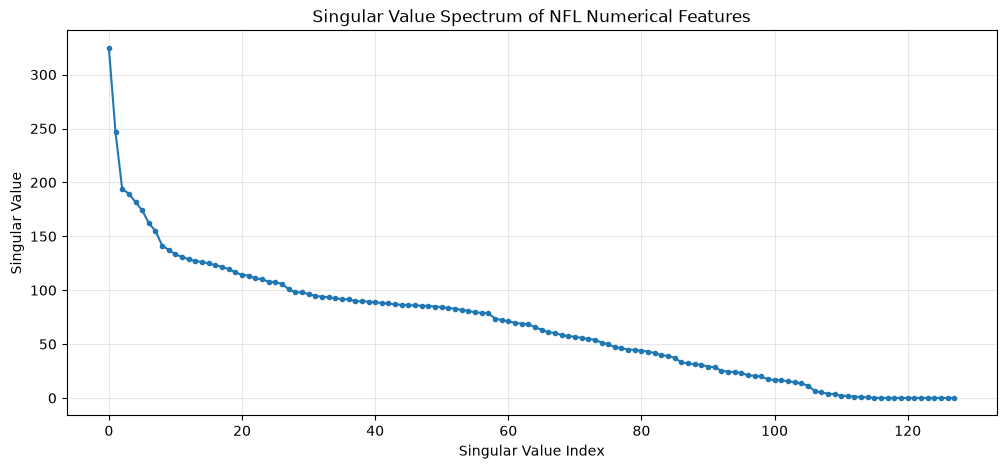

In [10]:

from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

# Standardize variables
X_scaled = StandardScaler().fit_transform(X_complete)

# Singular Value Decomposition
U, singular_values, Vt = np.linalg.svd(
    X_scaled,
    full_matrices=False
)

print("Numerical features:", X_scaled.shape[1])
print("Rank of standardized matrix:", np.linalg.matrix_rank(X_scaled))

print("\nSmallest 15 singular values:")
print(singular_values[-15:])

plt.figure(figsize=(12, 5))

plt.plot(
    singular_values,
    marker="o",
    markersize=3
)

plt.title("Singular Value Spectrum of NFL Numerical Features")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value")
plt.grid(alpha=0.3)

plt.show()


Original dimensions: 128
PCA components: 128
Variance explained by PC1: 0.1080664401142915
Variance explained by PC2: 0.06221005324061221


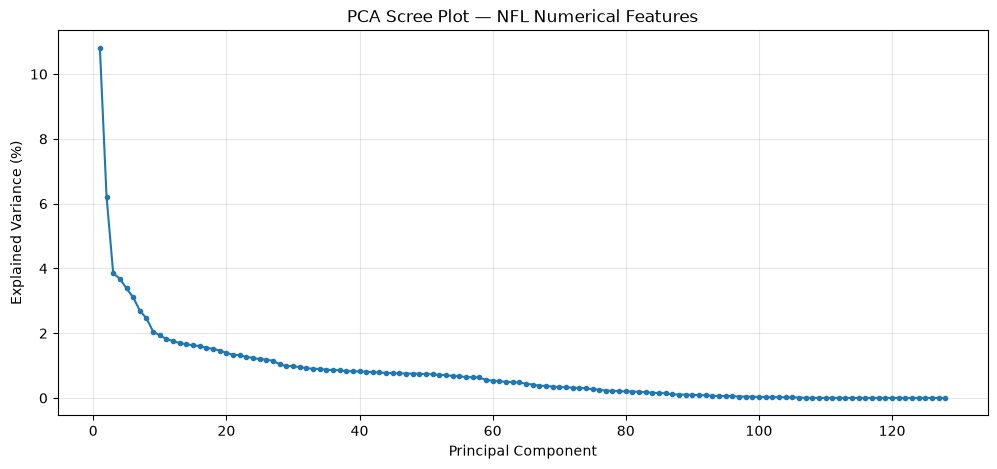

In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Standardize numerical features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_complete)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance ratios
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

print("Original dimensions:", X_complete.shape[1])
print("PCA components:", pca.n_components_)
print("Variance explained by PC1:", explained_variance[0])
print("Variance explained by PC2:", explained_variance[1])

#scree plot below

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    marker="o",
    markersize=3
)

plt.title("PCA Scree Plot — NFL Numerical Features")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.grid(alpha=0.3)

plt.show()



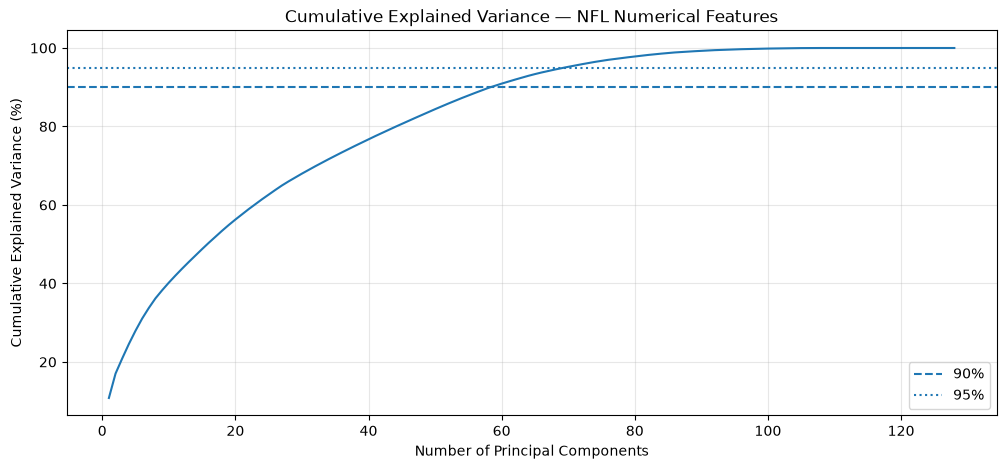

Components for 90% variance: 59
Components for 95% variance: 70


In [13]:
#culmalitve explained variance
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)

plt.axhline(90, linestyle="--", label="90%")
plt.axhline(95, linestyle=":", label="95%")

plt.title("Cumulative Explained Variance — NFL Numerical Features")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Components needed to explain 90% and 95% variance
n90 = np.searchsorted(cumulative_variance, 0.90) + 1
n95 = np.searchsorted(cumulative_variance, 0.95) + 1

print(f"Components for 90% variance: {n90}")
print(f"Components for 95% variance: {n95}")


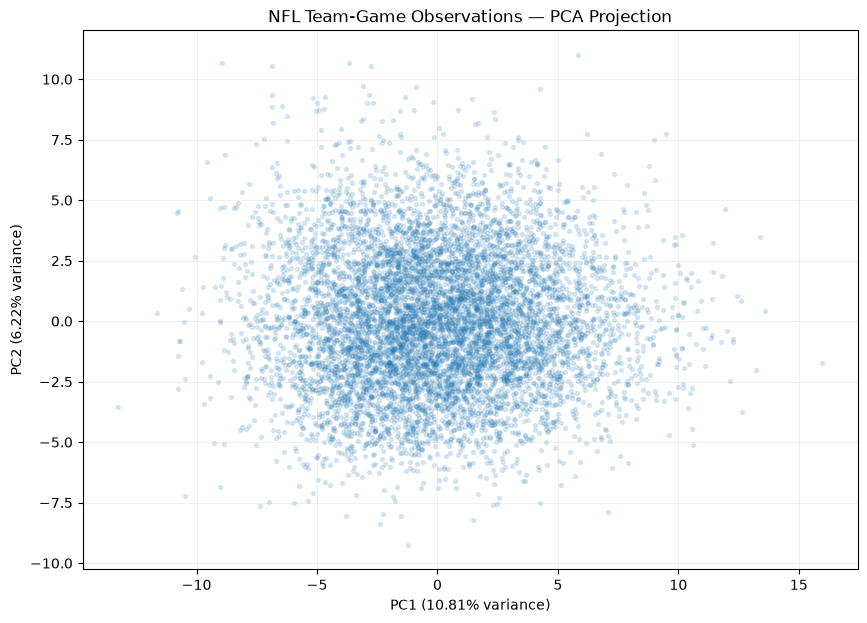

In [ ]:

# each point represnets one team-game observation 
# if a distnace cluster appears, we can investigate whether they,
# correspond to different offensive profiles, historical periods or other charactericitcs

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.15,
    s=8
)

plt.xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f}% variance)"
)

plt.title("NFL Team-Game Observations — PCA Projection")
plt.grid(alpha=0.2)

plt.show()


In [15]:

loadings = pd.DataFrame(
    pca.components_.T,
    index=X_complete.columns,
    columns=[
        f"PC{i+1}" for i in range(pca.n_components_)
    ]
)

# Top variables contributing to PC1 and PC2
for pc in ["PC1", "PC2"]:
    print(f"\nTop variables for {pc}")

    top_features = (
        loadings[pc]
        .sort_values(key=abs, ascending=False)
        .head(15)
    )

    display(top_features)



Top variables for PC1


passing_yards                  0.260280
receiving_yards                0.260280
passing_first_downs            0.240691
receiving_first_downs          0.240691
passing_10                     0.234851
receiving_10                   0.234844
receptions                     0.213462
completions                    0.213462
passing_16                     0.209288
receiving_16                   0.209233
passing_yards_after_catch      0.186739
receiving_yards_after_catch    0.186692
passing_20                     0.184504
receiving_20                   0.184427
attempts                       0.183774
Name: PC1, dtype: float64


Top variables for PC2


rushing_yards          0.246087
rushing_first_downs    0.236214
pat_att                0.234227
pat_made               0.228889
carries                0.222011
pt_yards              -0.207899
rushing_10             0.207098
pt_att                -0.203250
passing_epa            0.200532
rushing_12             0.200049
pt_net_yards          -0.199288
rushing_tds            0.178222
rushing_epa            0.160259
rushing_20             0.158237
attempts              -0.157266
Name: PC2, dtype: float64

In [5]:

missing_summary = (
    variable_audit
    .sort_values("Missing (%)", ascending=False)
)

display(missing_summary.head(25))


,Variable,Data Type,Missing Count,Missing (%),Unique Values
111,fg_blocked_list,str,12892,96.08,64
110,fg_missed_list,str,10054,74.93,397
19,passing_cpoe,float64,3031,22.59,10387
95,fg_long,float64,2584,19.26,51
109,fg_made_list,str,2584,19.26,4133
96,fg_pct,float64,1762,13.13,16
119,pat_pct,float64,1285,9.58,13
127,pt_long,float64,115,0.86,67
97,fg_made_0_19,int32,0,0.00,3
98,fg_made_20_29,int32,0,0.00,6


## Exploratory Linear Algebra and Principal Component Analysis (2000–2025)

### Research Objective

This investigation examined the numerical structure of the NFL weekly team-game dataset across 26 regular seasons (2000–2025).

The objective was to assess linear dependencies among numerical variables, examine the distribution of variance across different dimensions, and explore whether the dataset could be represented using fewer principal components.

### 1. Matrix Rank and Linear Dependence

The numerical feature matrix contained **13,418 observations and 128 variables**, following the exclusion of non-numerical fields, selected identifiers, and constant columns.

The centered numerical matrix exhibited a calculated rank of **116**, corresponding to a numerical rank deficiency of **12**.

This indicates that, under the numerical tolerance used, the matrix contained 116 linearly independent directions rather than the maximum possible 128.

These results suggest that certain numerical variables may contain redundant linear information, potentially arising from statistical identities or closely related measurements.

However, rank deficiency does not necessarily indicate invalid data. Derived statistics and mathematically related variables may legitimately produce linear dependencies.

### 2. Singular Value Decomposition (SVD)

Singular Value Decomposition was applied to the standardized numerical matrix to examine the relative magnitudes of its singular values.

The singular-value spectrum exhibited a pronounced decline among the earliest components, followed by a more gradual decrease across subsequent dimensions.

Several singular values approached zero toward the end of the spectrum, indicating directions with comparatively little variation and potential linear dependencies.

The analysis suggests that the dataset's numerical variation is distributed unevenly across its available dimensions.

### 3. Principal Component Analysis (PCA)

PCA was performed using standardized numerical variables to identify orthogonal directions that capture the greatest variation in team-game performance.

The first principal component (PC1) explained approximately **10.81%** of the total standardized variance, while the second principal component (PC2) explained approximately **6.22%**.

Together, the first two components accounted for approximately **17.03% of the total variance**.

The cumulative explained-variance analysis showed that:

- **59 principal components** were required to explain approximately 90% of the standardized variance.
- **70 principal components** were required to explain approximately 95% of the standardized variance.

These findings indicate that meaningful dimensionality reduction is possible, although the numerical variation is distributed across many components rather than concentrated in only a few.

### 4. Interpretation of Principal Component Loadings

Examination of the principal component loadings provided preliminary insight into the numerical characteristics represented by the first two components.

**PC1 — Passing and Receiving Production**

The variables with the largest absolute loadings included passing yards, receiving yards, passing first downs, receiving first downs, passing plays of at least 10 yards, receptions, and completions.

These relationships suggest that PC1 is strongly associated with passing and receiving production.

Several variables exhibited nearly identical loadings, consistent with potentially redundant or closely related measurements.

**PC2 — Rushing, Scoring, and Punting Activity**

PC2 exhibited relatively large positive loadings for rushing yards, rushing first downs, rushing attempts, and point-after-touchdown statistics.

Conversely, punting yards and attempts exhibited negative loadings.

This component may partially distinguish team-game performances characterized by greater rushing and scoring-related production from those associated with more punting activity.

These interpretations remain exploratory and should not be treated as definitive classifications of offensive performance.

### 5. Two-Dimensional PCA Visualization

The projection of team-game observations onto PC1 and PC2 produced a relatively dense, overlapping distribution without clearly separated clusters.

This suggests that the first two components alone do not reveal distinct groups of team-game performances.

However, because PC1 and PC2 explain only approximately 17% of the total standardized variance, the absence of visually distinct clusters does not establish that meaningful performance differences are absent.

Additional components or more targeted feature subsets may reveal relationships not visible in the two-dimensional projection.

### Statistical Limitations

This analysis primarily examined the mathematical structure of the dataset rather than the predictive importance of individual variables.

PCA identifies directions of maximum variance, but these directions do not necessarily correspond to variables that are most useful for predicting game outcomes or player performance.

Furthermore, derived statistics, differences in variable definitions, and the inclusion of highly related measurements may influence both matrix rank and principal component loadings.

The numerical rank is also sensitive to the tolerance and scaling used during computation.

Consequently, these findings should be interpreted as exploratory numerical diagnostics rather than evidence of causal relationships or independent predictive value.

### Conclusion

The analysis identified substantial numerical structure and redundancy within the NFL team-game dataset.

Although the centered feature matrix contained 128 numerical variables, its calculated rank was 116, suggesting that some dimensions were linearly dependent under the selected numerical tolerance.

PCA demonstrated that approximately 95% of the standardized variance could be represented using 70 principal components, indicating opportunities for dimensionality reduction.

The first two components appeared strongly associated with different aspects of offensive production, particularly passing and receiving activity for PC1 and rushing, scoring, and punting activity for PC2.

Overall, this investigation established an exploratory linear algebra framework that can be replicated in subsequent team-season, matchup-level, and player-level analyses.

Future research will investigate individual NFL teams, evaluate offensive production and consistency, and examine how statistical relationships differ across teams and seasons.